# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** I.V.G.Harsha Vardhan
**Roll Number:** AP24110012122
**Date:** 09/10/2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [3]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:*
 70/30 split has more entropy because With a 90/10 split, guessing is easy if you always guess the majority class, you'll be right 90% of the time, so uncertainty is low. A 70/30 split is much more balanced and mixed, making the outcome harder to guess correctly and increasing uncertainty.

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [10]:

h_parent = entropy([8, 6])
h_split = (6 / 14) * entropy([6, 0]) + (8 / 14) * entropy([2, 6])
info_gain = h_parent - h_split
print("Parent entropy   [8, 6] :", round(h_parent, 4))
print("Information Gain        :", round(info_gain, 4))


Parent entropy   [8, 6] : 0.9852
Information Gain        : 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [6]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [7]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted
print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [17]:
#1
def info_gain_func(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted
for attr in ['Outlook', 'Temperature', 'Humidity']:
  print(f"Gain({attr:11s}):", round(info_gain_func(tennis, attr), 4))
sunny_df = tennis[tennis['Outlook'] == 'Sunny']
print('\n--- Gains for Sunny Branch ---')
for attr in ['Temperature', 'Humidity', 'Wind']:
  print(f"Gain({attr:11s}):", round(info_gain_func(sunny_df, attr), 4))
rain_df = tennis[tennis['Outlook'] == 'Rain']
print('\n--- Gains for Rain Branch ---')
for attr in ['Temperature', 'Humidity', 'Wind']:
  print(f"Gain({attr:11s}):", round(info_gain_func(rain_df, attr), 4))

Gain(Outlook    ): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity   ): 0.1518

--- Gains for Sunny Branch ---
Gain(Temperature): 0.571
Gain(Humidity   ): 0.971
Gain(Wind       ): 0.02

--- Gains for Rain Branch ---
Gain(Temperature): 0.02
Gain(Humidity   ): 0.02
Gain(Wind       ): 0.971


2. The ID3 picks the Root Attribute as Outlook (has the highest Information Gain).

3.Next Splits for Non-Pure Branches:

For Outlook == 'Sunny': Split on Humidity (Gain = 0.9710).

For Outlook == 'Rain': Split on Wind (Gain = 0.9710).

**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:*
the pure branch need no further splitting because we do the entropy and information gain to get the purest node among all at the end.There is zero uncertainty or randomness left in that node.The classification decision for that path is already complete and accurate.so, if we get the purest node why should we do the splitting again after getting the purest node.

## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


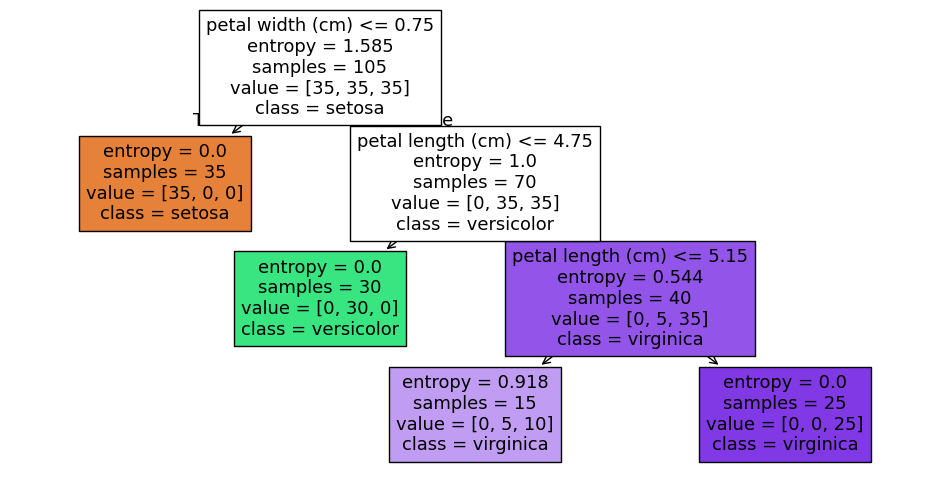

In [18]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


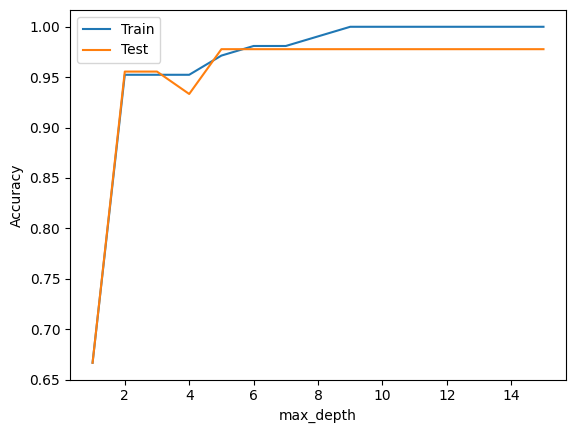

Best depth: 5 (Test Accuracy: 97.78%)


In [19]:
# Write your answer here
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
  t = DecisionTreeClassifier(
      criterion='entropy', max_depth=d, random_state=1
  ).fit(X_train, y_train)
  train_acc.append(accuracy_score(y_train, t.predict(X_train)))
  test_acc.append(accuracy_score(y_test, t.predict(X_test)))
plt.plot(depths, train_acc, label='Train')
plt.plot(depths, test_acc, label='Test')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
best_depth = depths[np.argmax(test_acc)]
print(
    f'Best depth: {best_depth} (Test Accuracy: {max(test_acc) * 100:.2f}%)'
)

**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:*polynomial degree,number of neighbours are the knobs in week 6,7 respectively.
week6:Low max_depth (or low degree / high $K$): Underfitting (high bias). Model is too simple and performs poorly on both train and test data.week7:High max_depth (or high degree / low $K$): Overfitting (high variance). Model memorizes training noise, giving high train accuracy but failing on test data.

# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [9]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Test accuracy (default): 0.8814814814814815
Max depth 3 test accuracy: 0.5296296296296297
Max depth 6 test accuracy: 0.8537037037037037
Max depth 10 test accuracy: 0.8796296296296297


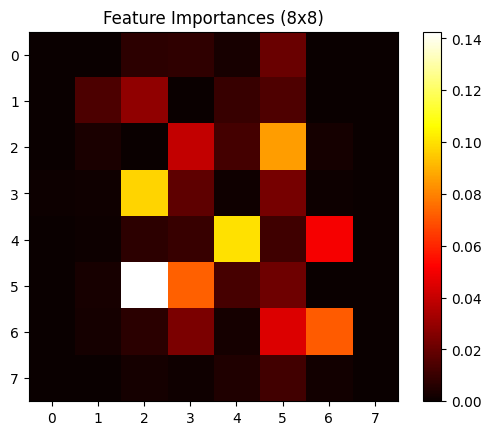

In [20]:
# Write your answer here
tree = DecisionTreeClassifier(criterion='entropy', random_state=1).fit(
    Xd_train, yd_train
)
print('Test accuracy (default):', accuracy_score(yd_test, tree.predict(Xd_test)))

for depth in [3, 6, 10]:
  t = DecisionTreeClassifier(
      criterion='entropy', max_depth=depth, random_state=1
  ).fit(Xd_train, yd_train)
  print(
      f'Max depth {depth} test accuracy:',
      accuracy_score(yd_test, t.predict(Xd_test)),
  )

importance = tree.feature_importances_.reshape(8, 8)
plt.imshow(importance, cmap='hot')
plt.colorbar()
plt.title('Feature Importances (8x8)')
plt.show()

**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*
The Decision Tree is less accurate than KNN on the digits dataset (~88% vs ~98%).
This is because the tree relies on only a few specific pixels in the center (shown by the bright spots on the heatmap), while ignoring the rest. KNN looks at all pixels together using continuous spatial distance, making it much better at recognizing whole digit shapes.

# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [4]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [6]:
# Write your answer here
tree = DecisionTreeClassifier(criterion='entropy', random_state=1).fit(
    X_text, labels
)
print(export_text(tree, feature_names=vocab))
s1 = 'the striker scored a goal'
s2 = 'the apple phone is fast'
pred1 = tree.predict(to_vector(s1, vocab).reshape(1, -1))[0]
pred2 = tree.predict(to_vector(s2, vocab).reshape(1, -1))[0]
print(f"'{s1}' -> {pred1}")
print(f"'{s2}' -> {pred2}")

|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

'the striker scored a goal' -> sports
'the apple phone is fast' -> sports


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:*
No,i would not expect the same split of the words because,
Words like "and" or "has" were picked by chance because of the tiny dataset. Adding more sentences would introduce meaningful topic words,changing the splits. This shows that trees trained on very little data easily overfit to random noise and cannot be trusted.

## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
